<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch6_gibbs_neuralnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the course's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('doe'):
        os.system('git clone -q -b main --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DoE.git doe')
        os.system('git -C doe sparse-checkout set Python/Data Python/Support')
    path = 'doe/Python/'

Neural net versus kriging for the Gibbs reactor (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).
Inputs $x_\omega=(P,T)$ (`X`, scaled), output conversion $y_\omega$ (`y`). The NN has one hidden layer
with two perceptrons (logistic activations) and is trained by minimizing the squared loss $L(\theta)$.

**Note:** This notebook reproduces Example 6.26 (Section 6.7.1) of *Statistics for Chemical Engineers*: a neural network model of the Gibbs reactor conversion.

**The concept.** A neural net with one hidden layer of $N$ perceptrons computes

$$a_j=\theta^I_{j,0}+\sum_i\theta^I_{j,i}\,x_i,\qquad h_j=\frac{1}{1+e^{-a_j}},\qquad \hat{y}=\theta^O_0+\sum_{j=1}^{N}\theta^O_j\,h_j.$$

Each perceptron takes a linear combination of the inputs (evidence), passes it through an activation, and the output layer mixes the results. With 2 inputs and $N=2$ there are $2\times2+2=6$ parameters in the hidden layer and $2+1=3$ in the output layer, 9 in total. Training minimizes the squared loss $L(\theta)=\frac{1}{2}\sum_\omega(y_\omega-\hat{y}_\omega)^2$ (the library divides it by $S$ and adds a very small ridge penalty). The inputs are scaled so that the perceptrons do not saturate.

NN parameters: 9;  MSE NN = 9.29e-04,  MSE kriging = 8.71e-04


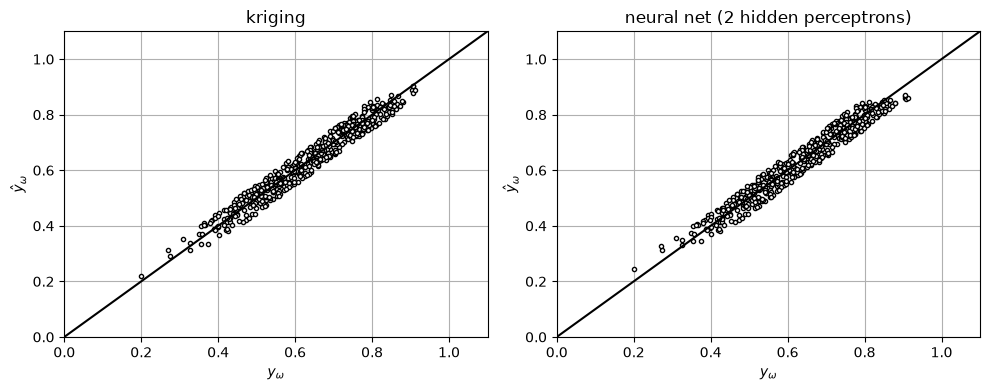

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel
from sklearn.preprocessing import StandardScaler

data = np.vstack((np.loadtxt(path+'Data/gibbs_hightemp_class.dat'),
                  np.loadtxt(path+'Data/gibbs_lowtemp_class.dat')))
S = len(data)
np.random.seed(0)
X = np.column_stack((data[:, 1], data[:, 0])) + np.random.rand(S, 2) * 0.1   # (P, T)
y = data[:, 2] + np.random.rand(S) * 0.1
X = StandardScaler().fit_transform(X)

nn = MLPRegressor(hidden_layer_sizes=(2,), activation='logistic', solver='lbfgs',
                  max_iter=20000, random_state=2024).fit(X, y)
y_nn = nn.predict(X)
gp = GaussianProcessRegressor(kernel=Matern(length_scale=1, nu=1.5) + WhiteKernel(0.01), normalize_y=True,
                              n_restarts_optimizer=5, random_state=0).fit(X, y)
y_gp = gp.predict(X)
n_params = sum(w.size for w in nn.coefs_) + sum(b.size for b in nn.intercepts_)
print(f"NN parameters: {n_params};  MSE NN = {np.mean((y - y_nn)**2):.2e},  MSE kriging = {np.mean((y - y_gp)**2):.2e}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in ((axs[0], y_gp, 'kriging'), (axs[1], y_nn, 'neural net (2 hidden perceptrons)')):
    ax.plot(y, pred, 'ko', markerfacecolor='w', markersize=3)
    ax.plot([0, 1.1], [0, 1.1], 'k-')
    ax.set_title(title); ax.set_xlabel(r'$y_\omega$'); ax.set_ylabel(r'$\hat{y}_\omega$')
    ax.axis([0, 1.1, 0, 1.1]); ax.grid(True)
plt.tight_layout()
plt.show()

**The math, from scratch.** The forward pass is two matrix products and one activation. `nn.coefs_` holds $\theta^I$ and $\theta^O$, and `nn.intercepts_` the biases.

In [3]:
a = X @ nn.coefs_[0] + nn.intercepts_[0]                 # evidence of the 2 perceptrons, S x 2
h = 1 / (1 + np.exp(-a))                                 # activation
y_hand = (h @ nn.coefs_[1] + nn.intercepts_[1]).ravel()  # output layer
print(f"largest difference from scikit-learn: {np.abs(y_hand - y_nn).max():.1e}")

largest difference from scikit-learn: 0.0e+00


**Note:** As in the book, a network with one layer and a few perceptrons fits this highly nonlinear model extremely well.